In [1]:
from model import VAE_Encoder_MNIST,Ganerator_MNIST
import torch
from torchvision import datasets, transforms
from torchvision.utils import save_image
import numpy as np
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
from com_utils import array_to_bits, bits_to_array,dequantization
from scipy.io import savemat
import os
from scipy.io import loadmat

In [6]:
# 測試接收到的訊號後做反量化
# 輸入bitstream

In [2]:
bits = 8
num = 0
ber_sum = 0
error_num = 0
# print("bits=",bits)\
# 讀檔
tx_data = loadmat(f'D:/matlab/result_20260317/latent_bits_M/bits_8/sample_000.mat')
rx_data = loadmat(f'D:/matlab/test20260329/A_1.mat')
tx_bits = tx_data['bits'].flatten().astype(np.uint8)
rx_bits = rx_data['A_1'].flatten().astype(np.uint8)
print("tx length:", len(tx_bits))
print("rx length:", len(rx_bits))
if len(tx_bits) != len(rx_bits):   
    # 如果長度不同，先截成相同長度
    L = min(len(tx_bits), len(rx_bits))
    tx_bits = tx_bits[:L]
    rx_bits = rx_bits[:L]
else:
    L = len(tx_bits)

bit_errors = np.sum(tx_bits != rx_bits)
ber = bit_errors / L
ber_sum = ber_sum + ber
print("Bit errors:", bit_errors)
print("Total bits:", L)
print("BER:", ber)

tx length: 512
rx length: 512
Bit errors: 2
Total bits: 512
BER: 0.00390625


In [3]:
# bit stream to array
rx_array = bits_to_array(rx_bits,bits)
print(rx_array)
# array to dequantization
rz_rec = dequantization(rx_array,bits)
print(rz_rec)

[  17  -55   76   16   26   66   -7  -21   98  -18   52   48 -127   49
  -38   63  -52  -71  -45  -12   57   37   62  -61  -63  -17   58  -43
   38   13   40    1  -37 -115   28  -27  -45   -8   46   29   -3   59
   -2   48   52   67   47   -2  -58  -96  -36  -54  112  -36  -57   44
   51  -18   10  -18 -104  -59   25  -48]
tensor([ 0.5490, -1.7098,  2.4000,  0.5176,  0.8314,  2.0863, -0.2039, -0.6431,
         3.0902, -0.5490,  1.6471,  1.5216, -3.9686,  1.5529, -1.1765,  1.9922,
        -1.6157, -2.2118, -1.3961, -0.3608,  1.8039,  1.1765,  1.9608, -1.8980,
        -1.9608, -0.5176,  1.8353, -1.3333,  1.2078,  0.4235,  1.2706,  0.0471,
        -1.1451, -3.5922,  0.8941, -0.8314, -1.3961, -0.2353,  1.4588,  0.9255,
        -0.0784,  1.8667, -0.0471,  1.5216,  1.6471,  2.1176,  1.4902, -0.0471,
        -1.8039, -2.9961, -1.1137, -1.6784,  3.5294, -1.1137, -1.7725,  1.3961,
         1.6157, -0.5490,  0.3294, -0.5490, -3.2471, -1.8353,  0.8000, -1.4902],
       device='cuda:0')


In [4]:
tx_array = bits_to_array(tx_bits,bits)
print(tx_array)
tz_rec = dequantization(tx_array,bits)
print(tz_rec)

[   1  -55   76   16   26   66   -7  -21   98  -18   52   48 -127   49
  -38   63  -52  -71  -45  -12   57   37   62  -61  -63  -17   58  -43
   38   13   40    1  -37 -115   28  -27  -45   -8   46   29   -3   59
   -2   48   52   67   47   -2  -58  -96  -40  -54  112  -36  -57   44
   51  -18   10  -18 -104  -59   25  -48]
tensor([ 0.0471, -1.7098,  2.4000,  0.5176,  0.8314,  2.0863, -0.2039, -0.6431,
         3.0902, -0.5490,  1.6471,  1.5216, -3.9686,  1.5529, -1.1765,  1.9922,
        -1.6157, -2.2118, -1.3961, -0.3608,  1.8039,  1.1765,  1.9608, -1.8980,
        -1.9608, -0.5176,  1.8353, -1.3333,  1.2078,  0.4235,  1.2706,  0.0471,
        -1.1451, -3.5922,  0.8941, -0.8314, -1.3961, -0.2353,  1.4588,  0.9255,
        -0.0784,  1.8667, -0.0471,  1.5216,  1.6471,  2.1176,  1.4902, -0.0471,
        -1.8039, -2.9961, -1.2392, -1.6784,  3.5294, -1.1137, -1.7725,  1.3961,
         1.6157, -0.5490,  0.3294, -0.5490, -3.2471, -1.8353,  0.8000, -1.4902],
       device='cuda:0')


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.MNIST(
    root="D:/Python/SemCom/saved_data",
    train=True,
    download=False,
    transform=transform
)

# dataloader
dl = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False)

In [6]:
z_dim = 64
G = Ganerator_MNIST(z_dim=z_dim).to(device)
G.load_state_dict(torch.load("./save_model/G_wgangp_C.pth"))
G.eval()
for p in G.parameters():
    p.requires_grad = False

In [9]:
# generator
# z_in = rz_rec.view(rz_rec.size(0), rz_rec.size(1), 1, 1)
rz_rec = rz_rec.unsqueeze(0)   # [D] -> [1, D]
rz_rec_in = rz_rec.view(rz_rec.size(0), rz_rec.size(1), 1, 1)

# reconstruct
with torch.no_grad():
    # x_gen_orig = G(z_in)
    x_gen_rec = G(rz_rec_in)

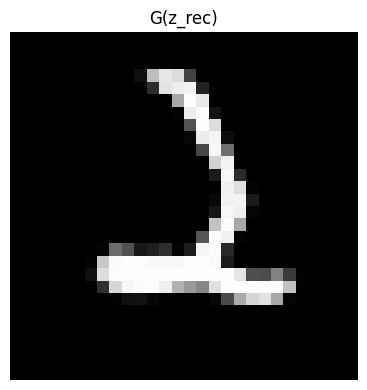

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(8,4))

# G(z)
# grid1 = make_grid((x_gen_orig + 1) / 2, nrow=8)
# img1 = grid1.permute(1,2,0).cpu().numpy()

# G(z_rec)
grid2 = make_grid((x_gen_rec + 1) / 2, nrow=8)
img2 = grid2.permute(1, 2, 0).cpu().numpy()

# ax[0].imshow(img1, cmap='gray')
# ax[0].set_title("G(z)")
# ax[0].axis("off")

ax.imshow(img2, cmap='gray')
ax.set_title("G(z_rec)")
ax.axis("off")

plt.tight_layout()
plt.show()
